# Calibração do CCA pela lei de Zipf — recorte interativo (GPW v4, 2020)

Versão interativa do `notebooks/01_Zipf_calibracao_CCA.ipynb`: o método é o mesmo, mas o recorte é escolhido
num mapa (seção 2) em vez de fixo na América do Norte. Com o recorte padrão, os resultados reproduzem os do
notebook original.

Os parâmetros do CCA ($D^*$, $\ell$) definem o que é uma "cidade" e, com isso, a população urbana de cada
bacia no `02_Micro_Plastic.ipynb`. Eles são escolhidos pelo critério da **lei de Zipf**: varremos a grade

* $D^* = 10, 20, \dots, 3000$ hab/km² (passo de 10 hab/km²),
* $\ell = 100, 200, \dots, 5000$ m (passo de 100 m),

calculamos para cada par o expoente $\alpha$ da lei de Zipf ($S(r) \propto r^{-\alpha}$, inclinação $-\alpha$
no rank-size) das maiores manchas e montamos a **matriz $D^* \times \ell$ colorida por $\alpha$**. A lei de Zipf
vale onde $\alpha = 1$.

O recorte tem de ser o mesmo do `02_Micro_Plastic.ipynb` desta pasta. Este notebook grava
`results/cca_calibracao_<TAG>.json` (com a caixa e as áreas excluídas), que o `02` lê.

## 1. Setup

In [8]:
import glob, os, subprocess, sys, zipfile

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rioxarray", "powerlaw"], check=True)

def local(caminho):
    """Procura o arquivo na pasta do notebook e, fora do Colab, na raiz do repositório e em dados/."""
    for base in (".", "..", "dados", os.path.join("..", "dados")):
        p = os.path.join(base, caminho)
        if os.path.exists(p):
            return p
    return None


def baixa_zip(id_drive, zip_destino, pasta):
    if local(pasta) is None:
        import gdown
        gdown.download(id=id_drive, output=zip_destino, quiet=True)
        zipfile.ZipFile(zip_destino).extractall(pasta)
    return local(pasta)


def baixa_arquivo(id_drive, destino):
    if local(destino) is None:
        import gdown
        gdown.download(id=id_drive, output=destino, quiet=True)
    return local(destino)


def clona(url, pasta):
    if not os.path.isdir(pasta):
        subprocess.run(["git", "clone", "-q", "--depth", "1", url, pasta], check=True)

GPW_DIR = baixa_zip("1c7nym3mWXzcy7iy_j1MQmCs4-RCZG0kO", "gpw_data.zip", "gpw_data")
NOAA_CSV = baixa_arquivo("1YssUUZS6CAQUXBjGOp1Aw-j8XwVeoP_y", "noaa_microplastics.csv")   # só para o mapa do recorte
clona("https://github.com/skaduhs5232/CCA.git", "CCA")

import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import rioxarray
import powerlaw
from numba import njit
from scipy import stats
from scipy import ndimage as ndi
sys.path.insert(0, "CCA")
from cca import cca_grid

os.makedirs("results", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "mathtext.fontset": "dejavuserif",
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 8.5, "legend.fontsize": 6.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "pdf.fonttype": 42,
})

## 2. Recorte da região: mapa interativo ou formulário

O pipeline roda em qualquer retângulo lon/lat do mundo. A segunda célula abaixo tem um formulário e, no Colab,
desenha um mapa com os sites do **Nurdle Patrol** (NOAA, *pieces/10 mins*, os únicos dados de lixo que entram
na análise), coloridos pela concentração média do site; passe o mouse sobre um ponto para ver o valor. As
amostras de outros métodos (redes de arrasto, sedimento) podem ser ligadas no seletor de camadas, só como
referência de onde há coleta.

**Como usar o mapa**

1. Rode as duas células. O retângulo azul é o recorte atual do formulário; os vermelhos, as áreas excluídas.
2. Com "o recorte (azul)" marcado, clique no ícone de retângulo (à esquerda do mapa) e arraste. Um recorte
   novo substitui o anterior.
3. Com "uma área excluída (vermelho)" marcado, cada retângulo desenhado vira uma máscara: os pixels dele viram
   oceano no relevo, têm a população zerada e as amostras descartadas. É assim que o recorte da tese corta a
   América do Sul no Canal do Panamá. Áreas excluídas que não tocam o recorte são ignoradas.
4. O lápis edita e a lixeira apaga retângulos. A cada mudança, o texto embaixo do mapa mostra as coordenadas
   e quantos sites caem no recorte, e o recorte é enviado ao Python.
5. Rode a célula de confirmação. Para seguir até o fim, use *Ambiente de execução → Executar a seguir* a
   partir dela.

**Formulário.** Se `USAR_MAPA` estiver desmarcado, ou fora do Colab (onde o mapa não consegue devolver as
coordenadas ao Python), valem os campos do formulário. O texto embaixo do mapa já sai no formato dos campos,
para copiar e colar, o que também serve para registrar o recorte usado. "Executar tudo" de uma vez roda a
confirmação antes de você desenhar, e aí vale o formulário.

Coordenadas em graus decimais (oeste e sul negativos), na ordem `lon_min, lat_min, lon_max, lat_max`, a mesma
de `BOX`; recortes que cruzam o antimeridiano (180°) não são aceitos. O padrão é o recorte da tese (América do
Norte até o Canal do Panamá). **Os dois notebooks precisam do mesmo recorte**: o `01` grava a calibração do
CCA junto com a caixa e as áreas excluídas, e o `02` só usa uma calibração feita para o mesmo recorte.

In [9]:
# Ferramentas do mapa: não precisa mexer aqui (o recorte se escolhe na célula seguinte)
import hashlib, uuid
from IPython.display import HTML, display
from matplotlib.colors import LogNorm, to_hex

EM_COLAB = "google.colab" in sys.modules
BOX_TESE = (-125.0, 7.0, -65.0, 50.0)
EXCLUIR_TESE = ((-79.0, -90.0, 180.0, 12.6),)    # América do Sul: a leste de 79°O e ao sul de 12,6°N

noaa_bruto = pd.read_csv(NOAA_CSV, low_memory=False)
e_nurdle = noaa_bruto["Unit"].eq("pieces/10 mins") & noaa_bruto["Standardized Nurdle  Amount"].notna()


def le_excluir(txt):
    """'x0, y0, x1, y1; x0, y0, x1, y1' -> lista de caixas (lon_min, lat_min, lon_max, lat_max)."""
    caixas = []
    for parte in str(txt).split(";"):
        parte = parte.strip().strip("()[]")
        if not parte:
            continue
        v = [float(s) for s in parte.split(",")]
        if len(v) != 4:
            raise ValueError(f"área excluída '{parte}': são 4 números, lon_min, lat_min, lon_max, lat_max")
        caixas.append(tuple(v))
    return caixas


def _dados_mapa(box, excluir):
    col = ["Latitude (degree)", "Longitude (degree)"]
    s = (noaa_bruto[e_nurdle].dropna(subset=col).groupby(col)["Standardized Nurdle  Amount"]
         .agg(["mean", "size"]).reset_index())
    cores = [to_hex(c) for c in plt.get_cmap("viridis")(LogNorm(1, 1e4)(s["mean"].clip(1, 1e4).to_numpy()))]
    nurdle = [[round(la, 4), round(lo, 4), "#ffffff" if m == 0 else c, round(m, 1), int(n)]
              for la, lo, m, n, c in zip(s[col[0]], s[col[1]], s["mean"], s["size"], cores)]
    outros = noaa_bruto.loc[~e_nurdle, col].dropna().round(3).drop_duplicates().to_numpy().tolist()
    return {"box": list(box), "excluir": [list(c) for c in excluir], "nurdle": nurdle, "outros": outros}


RECORTE_MAPA = {}


def _recebe_recorte(box, excluir, erro=None):
    RECORTE_MAPA.clear()
    if erro:
        RECORTE_MAPA["erro"] = erro
    else:
        RECORTE_MAPA.update(box=tuple(float(v) for v in box), excluir=[tuple(float(v) for v in c) for c in excluir])


if EM_COLAB:
    from google.colab import output as colab_output
    colab_output.register_callback("recorte.define", _recebe_recorte)


def mostra_mapa(box, excluir):
    dados = json.dumps(_dados_mapa(box, excluir), separators=(",", ":"))
    display(HTML(_HTML_MAPA.replace("__ID__", "rec" + uuid.uuid4().hex[:8]).replace("__DADOS__", dados)))


_HTML_MAPA = r"""
<div style="font:13px/1.4 sans-serif">
  <div style="margin:4px 0 6px">
    <b>A ferramenta de retângulo desenha:</b>
    <label style="margin-left:8px"><input type="radio" name="__ID__-modo" value="recorte" checked> o recorte (azul)</label>
    <label style="margin-left:12px"><input type="radio" name="__ID__-modo" value="excluir"> uma área excluída (vermelho)</label>
  </div>
  <div id="__ID__-mapa" style="height:540px;width:100%;border:1px solid #bbb"></div>
  <pre id="__ID__-saida" style="font:12px/1.4 monospace;background:#f4f4f4;padding:6px 8px;margin:6px 0 0;white-space:pre-wrap">carregando o mapa...</pre>
</div>
<script>
(function () {
  var ID = "__ID__", D = __DADOS__;
  var saida = document.getElementById(ID + "-saida");
  var COR = {recorte: "#0072B2", excluir: "#D55E00"};

  function js(url) {
    return new Promise(function (ok, erro) {
      var s = document.createElement("script");
      s.src = url;
      s.onload = ok;
      s.onerror = function () { erro(new Error(url)); };
      document.head.appendChild(s);
    });
  }
  function css(url) {
    var l = document.createElement("link");
    l.rel = "stylesheet";
    l.href = url;
    document.head.appendChild(l);
  }
  css("https://unpkg.com/leaflet@1.9.4/dist/leaflet.css");
  css("https://cdnjs.cloudflare.com/ajax/libs/leaflet.draw/1.0.4/leaflet.draw.css");
  // com um carregador AMD (require.js) na página, o Leaflet vira módulo e não cria o L global
  var amd = window.define;
  function restaura() { if (amd !== undefined) window.define = amd; }
  if (!(window.L && window.L.Draw)) window.define = undefined;
  (window.L && window.L.Draw ? Promise.resolve() : js("https://unpkg.com/leaflet@1.9.4/dist/leaflet.js").then(function () {
    return js("https://cdnjs.cloudflare.com/ajax/libs/leaflet.draw/1.0.4/leaflet.draw.js");
  })).then(function () {
    restaura();
    if (!window.L || !window.L.Draw) throw new Error("o Leaflet carregou mas não definiu L");
    inicia();
  }).catch(function (e) {
    restaura();
    saida.textContent = "Não foi possível carregar o Leaflet (" + e.message + "): use o formulário.";
  });

  function inicia() {
    var mapa = L.map(ID + "-mapa", {preferCanvas: true, worldCopyJump: true});
    var cinza = L.tileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}", {
      maxZoom: 16, attribution: "Esri, HERE, Garmin, &copy; OpenStreetMap"}).addTo(mapa);
    var osm = L.tileLayer("https://tile.openstreetmap.org/{z}/{x}/{y}.png", {
      maxZoom: 18, attribution: "&copy; OpenStreetMap"});

    var outros = L.layerGroup(D.outros.map(function (p) {
      return L.circleMarker([p[0], p[1]], {radius: 2, stroke: false, fillColor: "#777", fillOpacity: 0.6});
    }));
    var nurdle = L.layerGroup(D.nurdle.map(function (p) {
      return L.circleMarker([p[0], p[1]], {radius: 3.5, weight: 0.6, color: "#333", fillColor: p[2], fillOpacity: 0.9})
        .bindTooltip(p[3] + " pellets/10 min (média de " + p[4] + " amostra" + (p[4] > 1 ? "s" : "") + ")");
    })).addTo(mapa);
    L.control.layers({"Cinza (Esri)": cinza, "OpenStreetMap": osm}, {"Nurdle Patrol (entra na análise)": nurdle,
                            "Outros métodos (não entram)": outros}, {collapsed: false}).addTo(mapa);

    var legenda = L.control({position: "bottomright"});
    legenda.onAdd = function () {
      var d = L.DomUtil.create("div");
      d.style.cssText = "background:rgba(255,255,255,.9);padding:4px 6px;font:11px sans-serif;border-radius:3px";
      d.innerHTML = "Nurdle Patrol: pellets por 10 min (média do site)" +
        '<div style="height:8px;width:170px;margin-top:2px;background:linear-gradient(to right,#440154,#3b528b,#21918c,#5ec962,#fde725)"></div>' +
        '<div style="display:flex;justify-content:space-between;width:170px"><span>&le;1</span><span>100</span><span>&ge;10.000</span></div>' +
        '<span style="display:inline-block;width:8px;height:8px;border:1px solid #333;border-radius:50%;background:#fff"></span> zero';
      return d;
    };
    legenda.addTo(mapa);

    var camadas = new L.FeatureGroup().addTo(mapa);
    function modo() {
      return document.querySelector('input[name="' + ID + '-modo"]:checked').value;
    }
    function adiciona(l, tipo) {
      l.tipo = tipo;
      l.setStyle({color: COR[tipo], weight: 2, fillOpacity: tipo === "recorte" ? 0.04 : 0.25,
                  dashArray: tipo === "recorte" ? null : "5 4"});
      camadas.addLayer(l);
      return l;
    }
    var desenho = new L.Control.Draw({
      draw: {polyline: false, polygon: false, circle: false, marker: false, circlemarker: false,
             rectangle: {showArea: false, shapeOptions: {color: COR.recorte}}},
      edit: {featureGroup: camadas}});
    mapa.addControl(desenho);
    document.querySelectorAll('input[name="' + ID + '-modo"]').forEach(function (r) {
      r.addEventListener("change", function () {
        desenho.setDrawingOptions({rectangle: {showArea: false, shapeOptions: {color: COR[modo()]}}});
      });
    });

    function caixa(b) {
      var w = b.getWest(), e = b.getEast();
      var s = Math.max(b.getSouth(), -90), n = Math.min(b.getNorth(), 90);
      if (e - w >= 360) return {erro: "o retângulo dá a volta no mundo"};
      var k = Math.floor((w + 180) / 360);
      w -= 360 * k;
      e -= 360 * k;
      if (e > 180) return {erro: "o retângulo cruza o antimeridiano (180°)"};
      var r = function (v) { return Math.round(v * 100) / 100; };
      return {c: [r(w), r(s), r(e), r(n)]};
    }
    function cruza(a, b) {
      return a[0] < b[2] && b[0] < a[2] && a[1] < b[3] && b[1] < a[3];
    }
    function excluido(p, c) {
      return p[1] > c[0] && p[1] <= c[2] && p[0] >= c[1] && p[0] < c[3];
    }

    function envia() {
      var rec = null, exc = [], erros = [];
      camadas.eachLayer(function (l) {
        var r = caixa(l.getBounds());
        if (r.erro) erros.push(r.erro);
        else if (l.tipo === "recorte") rec = r.c;
        else exc.push(r.c);
      });
      if (erros.length) {
        manda([null, [], erros.join("; ")], "Recorte inválido: " + erros.join("; ") + ". Edite ou apague o retângulo.");
        return;
      }
      if (!rec) {
        manda([null, [], "nenhum recorte desenhado"], "Desenhe o recorte (modo azul) com a ferramenta de retângulo.");
        return;
      }
      var usadas = exc.filter(function (c) { return cruza(c, rec); });
      var n = 0, a = 0;
      D.nurdle.forEach(function (p) {
        if (p[1] >= rec[0] && p[1] <= rec[2] && p[0] >= rec[1] && p[0] <= rec[3] &&
            !usadas.some(function (c) { return excluido(p, c); })) {
          n += 1;
          a += p[4];
        }
      });
      var txt = "lon_min = " + rec[0] + "   lat_min = " + rec[1] + "   lon_max = " + rec[2] + "   lat_max = " + rec[3] +
        '\nEXCLUIR_TXT = "' + usadas.map(function (c) { return c.join(", "); }).join("; ") + '"' +
        "\n" + n + " sites do Nurdle Patrol (" + a + " amostras) no recorte, fora das áreas excluídas";
      if (exc.length > usadas.length) txt += "\n" + (exc.length - usadas.length) + " área(s) excluída(s) fora do recorte: ignorada(s)";
      if (n < 5) txt += "\nATENÇÃO: com menos de 5 sites não dá para ajustar a alometria";
      manda([rec, usadas, null], txt);
    }

    function manda(args, txt) {
      var ok = args[2] ? "" : "\nrecebido pelo Python: rode a célula de confirmação";
      if (window.google && google.colab && google.colab.kernel) {
        saida.textContent = txt + "\nenviando ao Python...";
        google.colab.kernel.invokeFunction("recorte.define", args, {}).then(function () {
          saida.textContent = txt + ok;
        }).catch(function (e) {
          saida.textContent = txt + "\nfalha ao enviar ao Python (" + e + "): copie os valores para o formulário";
        });
      } else {
        saida.textContent = txt + (args[2] ? "" :
          "\nFora do Colab o mapa não devolve o recorte ao Python: copie os valores para o formulário.");
      }
    }

    mapa.on(L.Draw.Event.CREATED, function (ev) {
      var tipo = modo();
      if (tipo === "recorte") camadas.eachLayer(function (l) { if (l.tipo === "recorte") camadas.removeLayer(l); });
      adiciona(ev.layer, tipo);
      envia();
    });
    mapa.on(L.Draw.Event.EDITED, envia);
    mapa.on(L.Draw.Event.DELETED, envia);

    var ini = adiciona(L.rectangle([[D.box[1], D.box[0]], [D.box[3], D.box[2]]]), "recorte");
    D.excluir.forEach(function (c) { adiciona(L.rectangle([[c[1], c[0]], [c[3], c[2]]]), "excluir"); });
    mapa.fitBounds(ini.getBounds().pad(0.15));
    setTimeout(function () { mapa.invalidateSize(); }, 300);
    envia();
  }
})();
</script>
"""

In [10]:
# @title Recorte da análise
# @markdown **Caixa do recorte**, em graus decimais (oeste e sul negativos):
lon_min = -125.0  # @param {type:"number"}
lat_min = 7.0  # @param {type:"number"}
lon_max = -65.0  # @param {type:"number"}
lat_max = 50.0  # @param {type:"number"}
# @markdown **Áreas excluídas**: `lon_min, lat_min, lon_max, lat_max`, várias separadas por `;` (vazio = nenhuma). O padrão corta a América do Sul no Canal do Panamá.
EXCLUIR_TXT = "-79, -90, 180, 12.6"  # @param {type:"string"}
# @markdown Desmarque para ignorar o mapa e usar só os campos acima:
USAR_MAPA = True  # @param {type:"boolean"}
# @markdown Fator de reamostragem do GEBCO para o IPBA (0 = automático; só o `02` usa):
FATOR_GEBCO_MANUAL = 0  # @param {type:"integer"}

BOX_FORM = (float(lon_min), float(lat_min), float(lon_max), float(lat_max))
EXCLUIR_FORM = le_excluir(EXCLUIR_TXT)
RECORTE_MAPA.clear()
if USAR_MAPA:
    mostra_mapa(BOX_FORM, EXCLUIR_FORM)
    if not EM_COLAB:
        print("Fora do Colab o mapa só mostra os dados e as coordenadas: copie-as para os campos do formulário.")

Fora do Colab o mapa só mostra os dados e as coordenadas: copie-as para os campos do formulário.


### Confirmação do recorte

Lê o recorte do mapa (ou do formulário), descarta as áreas excluídas que não tocam a caixa e deriva os
parâmetros que dependem do tamanho da região:

* `FATOR_GEBCO`: o IPBA é Python puro e grava os rótulos em `uint16`, então o relevo é reamostrado até caber
  num orçamento de ~2,4 milhões de pixels, o mesmo do recorte da tese (fator 8, 2′). Recortes menores ganham
  resolução (fator 1 = GEBCO nativo, 15″). Se o litoral ainda passar de 65.535 sinks, o `02` aumenta o fator
  sozinho. Um valor no campo `FATOR_GEBCO_MANUAL` substitui o automático.
* `FATOR_VIS` e `ESCALA_KM`: só para os desenhos.
* `TAG`: sufixo dos arquivos em `results/` (`na_panama` no recorte da tese, como nos notebooks originais).

Esta célula e as duas anteriores são idênticas nos dois notebooks.

In [11]:
if USAR_MAPA and RECORTE_MAPA.get("erro"):
    raise ValueError(f"o recorte do mapa não vale ({RECORTE_MAPA['erro']}): corrija no mapa ou desmarque USAR_MAPA")
if USAR_MAPA and RECORTE_MAPA:
    _box, _excl, ORIGEM_RECORTE = RECORTE_MAPA["box"], RECORTE_MAPA["excluir"], "mapa"
else:
    _box, _excl, ORIGEM_RECORTE = BOX_FORM, EXCLUIR_FORM, "formulário"
minx, miny, maxx, maxy = (float(v) for v in _box)
if not (-180 <= minx < maxx <= 180 and -90 <= miny < maxy <= 90):
    raise ValueError(f"recorte inválido {(minx, miny, maxx, maxy)}: é preciso -180 <= lon_min < lon_max <= 180 "
                     "e -90 <= lat_min < lat_max <= 90")
BOX = (minx, miny, maxx, maxy)
EXCLUIR = tuple(tuple(float(v) for v in c) for c in _excl
                if c[0] < maxx and minx < c[2] and c[1] < maxy and miny < c[3])


def excluido(lon, lat):
    """True nos pontos (ou pixels, com lon e lat em broadcast) que caem numa área excluída."""
    lon, lat = np.asarray(lon, dtype=float), np.asarray(lat, dtype=float)
    m = np.zeros(np.broadcast(lon, lat).shape, dtype=bool)
    for x0, y0, x1, y1 in EXCLUIR:
        m |= (lon > x0) & (lon <= x1) & (lat >= y0) & (lat < y1)
    return m


def mascara_excluida(da):
    """True nos pixels do raster que ficam fora da análise."""
    return excluido(da.x.values[None, :], da.y.values[:, None])


def _rotulo(v, pos, neg):
    return f"{abs(v):g}".replace(".", "p") + (pos if v >= 0 else neg)


if np.allclose(BOX, BOX_TESE) and sorted(EXCLUIR) == sorted(EXCLUIR_TESE):
    TAG = "na_panama"
else:
    TAG = "recorte_" + "_".join([_rotulo(minx, "E", "W"), _rotulo(miny, "N", "S"),
                                 _rotulo(maxx, "E", "W"), _rotulo(maxy, "N", "S")])
    if EXCLUIR:
        TAG += "_x" + hashlib.md5(repr(sorted(EXCLUIR)).encode()).hexdigest()[:4]

R_KM = 6371.0
largura_km = np.radians(maxx - minx) * R_KM * np.cos(np.radians((miny + maxy) / 2))
area_km2 = np.radians(maxx - minx) * (np.sin(np.radians(maxy)) - np.sin(np.radians(miny))) * R_KM ** 2
PIXELS_IPBA = 2.4e6                                          # ~ o recorte da tese: 1800 x 1290 pixels de 2′
px_gebco = (maxx - minx) * 240 * (maxy - miny) * 240         # GEBCO 2024: 15″ = 240 pixels por grau
FATOR_GEBCO = (int(FATOR_GEBCO_MANUAL) if FATOR_GEBCO_MANUAL > 0
               else max(1, int(np.ceil(np.sqrt(px_gebco / PIXELS_IPBA)))))
px_gpw = (maxx - minx) * 120 * (maxy - miny) * 120           # GPW v4: 30″
# o GPW tem mais pixels por lado do que cabem num painel: as camadas raster dele são desenhadas em blocos
# FATOR_VIS x FATOR_VIS (soma para população, máximo para as manchas), ~1200 blocos na largura
FATOR_VIS = max(1, int(round((maxx - minx) * 120 / 1200)))
ESCALA_KM = max([v for v in (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000) if v <= largura_km / 8], default=1)

lon_n, lat_n = noaa_bruto["Longitude (degree)"], noaa_bruto["Latitude (degree)"]
no_box = e_nurdle & lon_n.between(minx, maxx) & lat_n.between(miny, maxy) & ~excluido(lon_n, lat_n)
n_sites_box = noaa_bruto[no_box].groupby(["Longitude (degree)", "Latitude (degree)"]).ngroups

print(f"recorte (do {ORIGEM_RECORTE}): BOX = {BOX} | ~{largura_km:,.0f} km de largura, {area_km2:,.0f} km²")
print("áreas excluídas: " + ("; ".join(str(c) for c in EXCLUIR) if EXCLUIR else "nenhuma")
      + (f" ({len(_excl) - len(EXCLUIR)} fora da caixa, ignorada(s))" if len(_excl) > len(EXCLUIR) else ""))
frac_excl = excluido(np.linspace(minx, maxx, 400)[None, :], np.linspace(miny, maxy, 400)[:, None]).mean()
if frac_excl > 0.5:
    print(f"ATENÇÃO: as áreas excluídas cobrem {frac_excl:.0%} da caixa; se não era a intenção, apague-as no mapa "
          "ou esvazie EXCLUIR_TXT (o padrão do formulário corta a América do Sul)")
print(f"{n_sites_box} sites do Nurdle Patrol ({int(no_box.sum())} amostras) no recorte")
print(f"GEBCO: fator {FATOR_GEBCO} ({15 * FATOR_GEBCO / 60:g}′) -> ~{px_gebco / FATOR_GEBCO ** 2:,.0f} pixels no IPBA"
      f" | GPW: ~{px_gpw:,.0f} pixels | TAG = {TAG}")
if n_sites_box < 5:
    print("ATENÇÃO: menos de 5 sites do Nurdle Patrol no recorte; a alometria precisa de pelo menos 5 bacias com site")
if px_gpw > 1.5 * 7200 * 5160:
    print("ATENÇÃO: recorte bem maior que o da tese; o CCA e a varredura de Zipf vão pesar mais em memória e tempo")
if FATOR_GEBCO > 8:
    print(f"ATENÇÃO: com fator {FATOR_GEBCO} o pixel do relevo tem ~{FATOR_GEBCO * 0.46:.0f} km; bacias pequenas somem")

os.makedirs("results", exist_ok=True)
with open(f"results/recorte_{TAG}.json", "w", encoding="utf-8") as f:
    json.dump({"box": list(BOX), "excluir": [list(c) for c in EXCLUIR], "origem": ORIGEM_RECORTE, "tag": TAG},
              f, indent=2, ensure_ascii=False)

recorte (do formulário): BOX = (-125.0, 7.0, -65.0, 50.0) | ~5,863 km de largura, 27,380,903 km²
áreas excluídas: (-79.0, -90.0, 180.0, 12.6)
4814 sites do Nurdle Patrol (5783 amostras) no recorte
GEBCO: fator 8 (2′) -> ~2,322,000 pixels no IPBA | GPW: ~37,152,000 pixels | TAG = na_panama


### População no recorte

GPW v4 recortado pela caixa escolhida acima. Os pixels das áreas excluídas têm a população zerada (no recorte
da tese, a costa da Colômbia e da Venezuela que a caixa pega).

In [12]:
gpw = rioxarray.open_rasterio(glob.glob(os.path.join(GPW_DIR, "*.tif"))[0]).squeeze()
pop = gpw.rio.clip_box(minx=minx, miny=miny, maxx=maxx, maxy=maxy)
pop = pop.where(pop > 0, 0.0)
pop.rio.write_crs("EPSG:4326", inplace=True)
lon, lat = pop.x.values, pop.y.values
pop_px = np.where(mascara_excluida(pop), 0.0, np.nan_to_num(pop.values, nan=0.0)).astype(np.float64)

dx, dy = np.abs(pop.rio.resolution())
# a área do pixel varia com a latitude (fator cos), a mesma conta do cca_grid
area_px_km2 = ((dx * 111.32) * np.cos(np.radians(lat)))[:, None] * (dy * 111.32)
dens_km2 = pop_px / area_px_km2
print(f"GPW: {pop_px.shape[0]} x {pop_px.shape[1]} pixels | população do recorte: {pop_px.sum():,.0f}")

GPW: 5161 x 7201 pixels | população do recorte: 606,608,535


## 3. Varredura $(D^*, \ell)$

Rodar o `cca_grid` 15.000 vezes (300 valores de $D^*$ × 50 de $\ell$) num raster de dezenas de milhões de
pixels é inviável. Para cada $\ell$ fazemos uma única passada equivalente:

1. os pixels são **ativados em ordem decrescente de densidade**; ao ativar um pixel, ele é unido
   (*union-find*) a todo pixel já ativo a menos de $\ell$ (distância haversine entre os centros, como no `cca`);
2. quando a densidade do próximo pixel cai para $\leq D^*$, as manchas presentes são exatamente as do
   CCA com esse $D^*$ (ativação por densidade $> D^*$), então tiramos uma "fotografia" das populações;
3. descendo $D^*$ de 3000 até 10, uma passada produz as 300 colunas da matriz para aquele $\ell$.

**Expoente.** Para cada fotografia, $\alpha$ é medido nas $N$ maiores manchas pelo estimador de Hill (máxima
verossimilhança de Pareto): $\zeta = (N-1) / \sum_{i \le N} \ln(S_i / S_N)$ e $\alpha = 1/\zeta$. Um recorte
fixo em $N$ torna as células da matriz comparáveis entre si; escolher $x_{\min}$ célula a célula pela menor
distância KS (como numa versão anterior) fazia o ajuste saltar entre o corpo e a cauda da distribuição e
dava valores de $\alpha$ incoerentes com o ajuste completo. Calculamos $\alpha$ para $N = 50$, $100$ e $200$.

**$\ell$ mínimo.** Com $\ell$ menor que a distância diagonal entre centros de pixels vizinhos (~1,3 km neste
recorte) o CCA não liga pixels adjacentes: com $\ell < 0{,}93$ km nem os vizinhos norte-sul se ligam, e
qualquer área urbana contínua vira uma pilha de faixas leste-oeste. Essa faixa aparece na matriz, mas fica
fora da escolha.

In [13]:
D_GRADE = np.arange(10, 3001, 10)          # hab/km²
L_GRADE = np.arange(100, 5001, 100)        # metros
R_TERRA = 6378.137                         # km, o mesmo raio do pacote cca
nrows, ncols = dens_km2.shape
dens_f = dens_km2.ravel()
pop_f = pop_px.ravel()

# só entram na varredura os pixels ativados no menor D*, em ordem decrescente de densidade
ordem = np.flatnonzero(dens_f > D_GRADE.min())
ordem = ordem[np.argsort(-dens_f[ordem], kind="stable")].astype(np.int64)
print(f"{ordem.size:,} pixels com densidade > {D_GRADE.min()} hab/km²")


def vizinhanca(l_km):
    """Deslocamentos (di, dj) candidatos e, por linha do raster, se o par fica a menos de l (haversine)."""
    dlat, dlon = np.radians(dy), np.radians(dx)
    cos_min = np.cos(np.radians(np.abs(lat).max() + dy))
    ri = int(np.ceil(l_km / (R_TERRA * dlat)))
    rj = int(np.ceil(l_km / (R_TERRA * dlon * cos_min)))
    di, dj = np.meshgrid(np.arange(-ri, ri + 1), np.arange(-rj, rj + 1), indexing="ij")
    fora = (di == 0) & (dj == 0)
    di, dj = di[~fora], dj[~fora]
    passo_lat = np.radians(lat[1] - lat[0])
    lat0 = np.radians(lat)[:, None]
    lat1 = lat0 + di[None, :] * passo_lat
    h = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dj[None, :] * dlon / 2) ** 2
    valido = 2 * R_TERRA * np.arcsin(np.sqrt(np.clip(h, 0, 1))) < l_km
    usados = valido.any(axis=0)
    return di[usados].astype(np.int64), dj[usados].astype(np.int64), np.ascontiguousarray(valido[:, usados])


@njit
def _raiz(pai, p):
    r = p
    while pai[r] != r:
        r = pai[r]
    while pai[p] != r:
        q = pai[p]
        pai[p] = r
        p = q
    return r


@njit
def ativa_ate(D, pos, ordem, dens, popv, pai, tam, soma, ativo, di, dj, valido, nrows, ncols):
    """Ativa (em ordem decrescente) os pixels com densidade > D e une cada um aos vizinhos ativos a menos de l."""
    n = ordem.size
    while pos < n:
        p = ordem[pos]
        if dens[p] <= D:
            break
        ativo[p] = True
        pai[p] = p
        tam[p] = 1
        soma[p] = popv[p]
        r = p // ncols
        c = p - r * ncols
        for k in range(di.size):
            if not valido[r, k]:
                continue
            rr = r + di[k]
            cc = c + dj[k]
            if rr < 0 or rr >= nrows or cc < 0 or cc >= ncols:
                continue
            q = rr * ncols + cc
            if ativo[q]:
                a = _raiz(pai, p)
                b = _raiz(pai, q)
                if a != b:
                    if tam[a] < tam[b]:
                        a, b = b, a
                    pai[b] = a
                    tam[a] += tam[b]
                    soma[a] += soma[b]
        pos += 1
    return pos


@njit
def pops_manchas(ordem, pos, pai, soma):
    out = np.empty(pos)
    m = 0
    for i in range(pos):
        p = ordem[i]
        if pai[p] == p:
            out[m] = soma[p]
            m += 1
    return out[:m]


N_TOPO = (50, 100, 200)


def alpha_hill(x, n):
    """Inclinação do rank-size das n maiores manchas: alpha = 1/zeta, zeta de Hill = (n-1) / sum ln(S_i/S_n)."""
    if x.size < n:
        return np.nan
    s = np.partition(x, x.size - n)[-n:]
    return float(np.sum(np.log(s / s.min())) / (n - 1))


i_eq = int(np.abs(lat).argmin())
lat0, lat1 = np.radians(lat[i_eq]), np.radians(lat[i_eq] + dy)
diag_km = 2 * R_TERRA * np.arcsin(np.sqrt(np.sin((lat1 - lat0) / 2) ** 2
                                          + np.cos(lat0) * np.cos(lat1) * np.sin(np.radians(dx) / 2) ** 2))
L_MIN = int(np.ceil(diag_km * 10) * 100)
print(f"diagonal entre pixels vizinhos: até {diag_km * 1000:.0f} m -> escolha só com l >= {L_MIN} m")

4,095,500 pixels com densidade > 10 hab/km²
diagonal entre pixels vizinhos: até 1307 m -> escolha só com l >= 1400 m


In [14]:
forma = (len(L_GRADE), len(D_GRADE))
M = {c: np.full(forma, np.nan) for c in [f"alpha{n}" for n in N_TOPO] + ["n_manchas", "maior"]}

pai = np.zeros(dens_f.size, dtype=np.int64)
tam = np.zeros(dens_f.size, dtype=np.int64)
soma = np.zeros(dens_f.size)
ativo = np.zeros(dens_f.size, dtype=np.bool_)

t0 = time.time()
chave_ant = None
for i, l_m in enumerate(L_GRADE):
    di, dj, valido = vizinhanca(l_m / 1000)
    # l menor que o espaçamento dos pixels (ou que não muda nenhum par) repete a linha anterior
    chave = (di.tobytes(), dj.tobytes(), valido.tobytes())
    if chave == chave_ant:
        for c in M:
            M[c][i] = M[c][i - 1]
        continue
    chave_ant = chave
    ativo[ordem] = False
    pos = 0
    for j in range(len(D_GRADE) - 1, -1, -1):          # D* decrescente: a ativação só acumula
        pos = ativa_ate(float(D_GRADE[j]), pos, ordem, dens_f, pop_f, pai, tam, soma, ativo,
                        di, dj, valido, nrows, ncols)
        x = pops_manchas(ordem, pos, pai, soma)
        for n in N_TOPO:
            M[f"alpha{n}"][i, j] = alpha_hill(x, n)
        M["n_manchas"][i, j] = x.size
        M["maior"][i, j] = x.max() if x.size else np.nan
    print(f"l = {l_m:>4} m | {di.size:>3} vizinhos | alpha(N=50) de {np.nanmin(M['alpha50'][i]):.2f} a "
          f"{np.nanmax(M['alpha50'][i]):.2f} | {time.time() - t0:,.0f} s")

np.savez_compressed(f"results/zipf_matriz_{TAG}.npz", D_star=D_GRADE, l_metros=L_GRADE, L_MIN=L_MIN, **M)

l =  100 m |   0 vizinhos | alpha(N=50) de 0.64 a 0.64 | 2 s
l =  600 m |   2 vizinhos | alpha(N=50) de 0.64 a 0.66 | 4 s
l =  700 m |   2 vizinhos | alpha(N=50) de 0.27 a 0.55 | 6 s
l =  800 m |   2 vizinhos | alpha(N=50) de 0.28 a 0.42 | 7 s
l =  900 m |   2 vizinhos | alpha(N=50) de 0.27 a 0.44 | 9 s
l = 1000 m |   4 vizinhos | alpha(N=50) de 0.74 a 1.26 | 10 s
l = 1200 m |  10 vizinhos | alpha(N=50) de 0.74 a 1.38 | 12 s
l = 1300 m |  10 vizinhos | alpha(N=50) de 0.74 a 1.39 | 14 s
l = 1400 m |  10 vizinhos | alpha(N=50) de 0.74 a 1.39 | 15 s
l = 1500 m |  10 vizinhos | alpha(N=50) de 0.79 a 1.39 | 17 s
l = 1600 m |  14 vizinhos | alpha(N=50) de 0.77 a 1.40 | 19 s
l = 1700 m |  14 vizinhos | alpha(N=50) de 0.76 a 1.46 | 20 s
l = 1800 m |  16 vizinhos | alpha(N=50) de 0.77 a 1.45 | 22 s
l = 1900 m |  18 vizinhos | alpha(N=50) de 0.81 a 1.45 | 24 s
l = 2000 m |  22 vizinhos | alpha(N=50) de 0.80 a 1.45 | 26 s
l = 2100 m |  26 vizinhos | alpha(N=50) de 0.80 a 1.43 | 28 s
l = 2200 m | 

## 4. Matriz $D^* \times \ell$ e escolha dos parâmetros

Se as manchas seguem a lei de Zipf, $\alpha = 1$ vale **qualquer que seja o número $N$ de manchas usado no
ajuste**: o rank-size é uma reta de inclinação $-1$. Quando o rank-size é curvo, $\alpha$ muda com $N$ e a
curva $\alpha = 1$ de um $N$ não coincide com a de outro (painel a). O par escolhido é o que minimiza o pior
desvio entre os três recortes,

$$\Delta(D^*, \ell) = \max_{N \in \{50, 100, 200\}} |\alpha_N - 1|,$$

entre as células com $\ell \geq \ell_{\min}$ (painel b). Num recorte pequeno, que nunca chega a 200 (ou
100) manchas, esses $N$ saem do critério e o aviso abaixo diz quais ficaram. A tabela abaixo da figura lista, para cada $\ell$, o
$D^*$ de menor $\Delta$, para discutir a escolha.

Escolha: D* = 1010 hab/km², l = 1700 m | alpha(N=50) = 0.925, alpha(N=100) = 0.939, alpha(N=200) = 1.081 | Delta = 0.081 | 12185 manchas


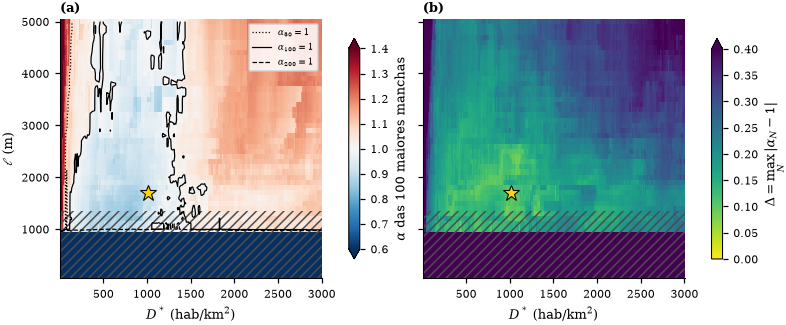

 l_m  D_star  delta  alpha50  alpha100  alpha200
1400     960  0.081    0.919     0.926     1.053
1500     970  0.088    0.917     0.912     1.079
1600    1040  0.098    0.903     0.917     1.098
1700    1010  0.081    0.925     0.939     1.081
1800     630  0.090    0.910     0.915     1.088
1900     820  0.091    0.959     0.909     1.089
2000     850  0.097    0.942     0.903     1.096
2100    1110  0.090    0.936     0.945     1.090
2200    1100  0.093    0.963     0.950     1.093
2300    1110  0.083    0.965     0.942     1.083
2400    1110  0.085    0.952     0.947     1.085
2500    1110  0.100    0.962     0.959     1.100
2600    1110  0.108    0.961     0.965     1.108
2700     420  0.131    0.880     0.912     1.131
2800     460  0.133    0.950     0.969     1.133
2900     460  0.135    0.865     1.008     1.133
3000     460  0.136    0.867     0.983     1.136
3100     460  0.144    0.870     0.985     1.144
3200     590  0.145    0.944     0.990     1.145
3300     670  0.146 

In [15]:
ok_l = L_GRADE >= L_MIN
N_USADOS = tuple(n for n in N_TOPO if np.isfinite(M[f"alpha{n}"][ok_l]).any())
if not N_USADOS:
    raise RuntimeError(f"nenhum par (D*, l) com l >= {L_MIN} m chega a {min(N_TOPO)} manchas: o recorte é "
                       "pequeno demais para a lei de Zipf")
if N_USADOS != N_TOPO:
    print(f"ATENÇÃO: o recorte nunca chega a {min(set(N_TOPO) - set(N_USADOS))} manchas; o critério usa só "
          f"N em {N_USADOS}")
N_MAPA = 100 if 100 in N_USADOS else N_USADOS[-1]
ESTILO_N = dict(zip(N_TOPO, (":", "-", "--")))
A = np.stack([M[f"alpha{n}"] for n in N_USADOS])
desvio = np.max(np.abs(A - 1), axis=0)
permitido = ok_l[:, None] & np.isfinite(desvio)
i_esc, j_esc = np.unravel_index(np.nanargmin(np.where(permitido, desvio, np.nan)), desvio.shape)
D_esc, l_esc = int(D_GRADE[j_esc]), int(L_GRADE[i_esc])
alphas_esc = {n: float(M[f"alpha{n}"][i_esc, j_esc]) for n in N_USADOS}
criterio = f"min max_N |alpha_N - 1|, N em {N_USADOS}, l >= {L_MIN} m"
print(f"Escolha: D* = {D_esc} hab/km², l = {l_esc} m | "
      + ", ".join(f"alpha(N={n}) = {a:.3f}" for n, a in alphas_esc.items())
      + f" | Delta = {desvio[i_esc, j_esc]:.3f} | {int(M['n_manchas'][i_esc, j_esc])} manchas")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True, sharey=True)
extent = (D_GRADE[0] - 5, D_GRADE[-1] + 5, L_GRADE[0] - 50, L_GRADE[-1] + 50)
im = axes[0].imshow(M[f"alpha{N_MAPA}"], origin="lower", aspect="auto", extent=extent, cmap="RdBu_r",
                    norm=TwoSlopeNorm(vmin=0.6, vcenter=1.0, vmax=1.4), interpolation="nearest")
for n in N_USADOS:
    axes[0].contour(D_GRADE, L_GRADE, M[f"alpha{n}"], levels=[1.0], colors="k", linewidths=0.8,
                    linestyles=ESTILO_N[n])
fig.colorbar(im, ax=axes[0], shrink=0.85, label=rf"$\alpha$ das {N_MAPA} maiores manchas", extend="both")
im = axes[1].imshow(desvio, origin="lower", aspect="auto", extent=extent, cmap="viridis_r",
                    vmin=0, vmax=0.4, interpolation="nearest")
fig.colorbar(im, ax=axes[1], shrink=0.85, label=r"$\Delta = \max_N |\alpha_N - 1|$", extend="max")
for ax, l in zip(axes, "ab"):
    ax.axhspan(extent[2], L_MIN - 50, facecolor="none", edgecolor="0.3", hatch="////", lw=0)
    ax.plot(D_esc, l_esc, marker="*", ms=11, mfc="gold", mec="k", mew=0.7, ls="")
    ax.set_xlabel(r"$D^*$ (hab/km$^2$)")
    ax.text(0.0, 1.015, f"({l})", transform=ax.transAxes, fontweight="bold", va="bottom")
axes[0].legend(handles=[plt.Line2D([], [], c="k", lw=0.8, ls=ESTILO_N[n], label=rf"$\alpha_{{{n}}} = 1$")
                        for n in N_USADOS], loc="upper right", fontsize=6,
               frameon=True, framealpha=0.85)
axes[0].set_ylabel(r"$\ell$ (m)")
fig.savefig(f"results/zipf_matriz_{TAG}.pdf")
fig.savefig(f"results/zipf_matriz_{TAG}.png")
plt.show()

linhas = []
for i, l in enumerate(L_GRADE):
    if l < L_MIN or not np.isfinite(desvio[i]).any():
        continue
    j = int(np.nanargmin(desvio[i]))
    linhas.append({"l_m": int(l), "D_star": int(D_GRADE[j]), "delta": desvio[i, j],
                   **{f"alpha{n}": M[f"alpha{n}"][i, j] for n in N_USADOS}})
curva = pd.DataFrame(linhas)
curva.to_csv(f"results/zipf_curva_alpha1_{TAG}.csv", index=False)
print(curva.round(3).to_string(index=False))

## 5. Ajuste completo no par escolhido

Roda o `cca_grid` (o mesmo do `02_Micro_Plastic.ipynb`) com o $(D^*, \ell)$ escolhido e confere que as manchas
e os expoentes batem com a varredura. Em seguida, como verificação independente, o ajuste de
Clauset–Shalizi–Newman completo, que escolhe o próprio $x_{\min}$ e testa a bondade de ajuste por bootstrap.

In [16]:
cidades, pop_cid, area_cid = cca_grid(pop_px, lon, lat, area_px_km2, D_esc, l_esc / 1000)
n_cca = len(pop_cid)
print(f"cca_grid: {n_cca} manchas, maior {pop_cid.max():,.0f} hab | varredura: "
      f"{int(M['n_manchas'][i_esc, j_esc])} manchas, maior {M['maior'][i_esc, j_esc]:,.0f} hab")
print("alpha de Hill no cca_grid: " + ", ".join(f"N={n}: {alpha_hill(pop_cid, n):.3f}" for n in N_USADOS))
if n_cca != int(M["n_manchas"][i_esc, j_esc]):
    print("ATENÇÃO: a varredura não reproduz o cca_grid neste par; confira a vizinhança antes de usar a matriz")

borda = np.zeros(n_cca + 1, dtype=bool)
for faixa in (cidades[0, :], cidades[-1, :], cidades[:, 0], cidades[:, -1]):
    borda[np.unique(faixa)] = True
centro = np.array(ndi.center_of_mass(pop_px, cidades, index=np.arange(1, n_cca + 1)))

# cidades de referência para nomear as manchas; só entram as que caem no recorte
REFS_MUNDO = {
    # América do Norte e Caribe (a lista dos notebooks originais, na mesma ordem)
    "Cidade do México": (-99.13, 19.43), "Nova York": (-74.00, 40.71), "Los Angeles": (-118.24, 34.05),
    "Chicago": (-87.63, 41.88), "Houston": (-95.37, 29.76), "Miami": (-80.19, 25.76),
    "Filadélfia": (-75.16, 39.95), "Washington": (-77.04, 38.91), "Boston": (-71.06, 42.36),
    "São Francisco": (-122.42, 37.77), "Seattle": (-122.33, 47.61), "Toronto": (-79.38, 43.65),
    "Montreal": (-73.57, 45.50), "Guadalajara": (-103.35, 20.67), "Monterrey": (-100.31, 25.69),
    "Dallas": (-96.80, 32.78), "Atlanta": (-84.39, 33.75), "Phoenix": (-112.07, 33.45),
    "Detroit": (-83.05, 42.33), "Puebla": (-98.20, 19.04), "San Diego/Tijuana": (-117.04, 32.62),
    "Nova Orleans": (-90.07, 29.95), "Tampa": (-82.46, 27.95), "Havana": (-82.37, 23.11),
    "Santo Domingo": (-69.93, 18.49), "Porto Príncipe": (-72.33, 18.54),
    "Cidade da Guatemala": (-90.51, 14.63), "San Salvador": (-89.19, 13.69),
    "Cidade do Panamá": (-79.52, 8.98), "Corpus Christi": (-97.40, 27.80), "Veracruz": (-96.13, 19.18),
    "Vancouver": (-123.12, 49.28), "Honolulu": (-157.86, 21.31),
    # América do Sul
    "São Paulo": (-46.63, -23.55), "Rio de Janeiro": (-43.17, -22.91), "Buenos Aires": (-58.38, -34.60),
    "Lima": (-77.04, -12.05), "Bogotá": (-74.07, 4.71), "Santiago": (-70.67, -33.45),
    "Belo Horizonte": (-43.94, -19.92), "Caracas": (-66.90, 10.48), "Medellín": (-75.57, 6.25),
    "Recife": (-34.88, -8.05), "Salvador": (-38.50, -12.97), "Fortaleza": (-38.53, -3.73),
    "Porto Alegre": (-51.23, -30.03), "Guayaquil": (-79.89, -2.19),
    # Europa
    "Londres": (-0.13, 51.51), "Paris": (2.35, 48.86), "Madri": (-3.70, 40.42), "Barcelona": (2.17, 41.39),
    "Lisboa": (-9.14, 38.72), "Roma": (12.50, 41.90), "Milão": (9.19, 45.46), "Berlim": (13.40, 52.52),
    "Amsterdã": (4.90, 52.37), "Atenas": (23.73, 37.98), "Istambul": (28.98, 41.01), "Moscou": (37.62, 55.76),
    # África e Oriente Médio
    "Cairo": (31.24, 30.04), "Alexandria": (29.92, 31.20), "Lagos": (3.38, 6.52), "Kinshasa": (15.27, -4.44),
    "Luanda": (13.23, -8.84), "Joanesburgo": (28.05, -26.20), "Cidade do Cabo": (18.42, -33.92),
    "Durban": (31.02, -29.86), "Nairóbi": (36.82, -1.29), "Adis Abeba": (38.75, 9.03), "Dacar": (-17.47, 14.72),
    "Abidjan": (-4.01, 5.36), "Acra": (-0.19, 5.60), "Teerã": (51.39, 35.69), "Bagdá": (44.36, 33.31),
    "Riad": (46.68, 24.71),
    # Ásia e Oceania
    "Tóquio": (139.69, 35.69), "Osaka": (135.50, 34.69), "Nagoya": (136.91, 35.18), "Seul": (126.98, 37.57),
    "Pequim": (116.41, 39.90), "Tianjin": (117.20, 39.08), "Xangai": (121.47, 31.23), "Guangzhou": (113.26, 23.13),
    "Shenzhen": (114.06, 22.54), "Hong Kong": (114.17, 22.32), "Chongqing": (106.55, 29.56),
    "Taipé": (121.56, 25.03), "Manila": (120.98, 14.60), "Jacarta": (106.85, -6.21), "Bangkok": (100.50, 13.76),
    "Ho Chi Minh": (106.63, 10.82), "Kuala Lumpur": (101.69, 3.14), "Singapura": (103.82, 1.35),
    "Daca": (90.41, 23.81), "Calcutá": (88.36, 22.57), "Délhi": (77.21, 28.61), "Mumbai": (72.88, 19.08),
    "Bangalore": (77.59, 12.97), "Chennai": (80.27, 13.08), "Hyderabad": (78.49, 17.39),
    "Karachi": (67.01, 24.86), "Lahore": (74.35, 31.55), "Sydney": (151.21, -33.87),
    "Melbourne": (144.96, -37.81), "Auckland": (174.76, -36.85),
}
refs = {nome: c for nome, c in REFS_MUNDO.items()
        if minx <= c[0] <= maxx and miny <= c[1] <= maxy and not excluido(*c)}


def nomeia(cidades, pesos, lon, lat, refs, janela=3):
    """Mancha de cada cidade de referência: a mais populosa numa janela de ±janela pixels em volta da
    coordenada (o pixel exato pode não ser urbano: parque, rio, baía)."""
    nomes = {}
    for nome, (lo, la) in refs.items():
        r, c = int(np.abs(lat - la).argmin()), int(np.abs(lon - lo).argmin())
        jan = (slice(max(r - janela, 0), r + janela + 1), slice(max(c - janela, 0), c + janela + 1))
        w, p = cidades[jan], pesos[jan]
        if (w > 0).any():
            ids_w, inv = np.unique(w[w > 0], return_inverse=True)
            nomes.setdefault(int(ids_w[np.bincount(inv, weights=p[w > 0]).argmax()]), nome)
    return nomes


nomes = nomeia(cidades, pop_px, lon, lat, refs)
df = pd.DataFrame({"cluster": np.arange(1, n_cca + 1), "pop": pop_cid, "area_km2": area_cid, "borda": borda[1:],
                   "lon": np.interp(centro[:, 1], np.arange(lon.size), lon),
                   "lat": np.interp(centro[:, 0], np.arange(lat.size), lat)})
df["nome"] = df["cluster"].map(nomes)
df = df[df["pop"] > 0].reset_index(drop=True)
df.to_csv(f"results/zipf_clusters_{TAG}.csv", index=False)

cca_grid: 12185 manchas, maior 20,602,596 hab | varredura: 12185 manchas, maior 20,602,596 hab
alpha de Hill no cca_grid: N=50: 0.925, N=100: 0.939, N=200: 1.081


### Ajuste da lei de potência (Clauset–Shalizi–Newman, 2009)

Duas formas equivalentes de enunciar a mesma lei:

* **rank-size** (a forma clássica de Zipf): $S(r) \propto r^{-\alpha}$
* **distribuição** de tamanhos: $p(x) \propto x^{-\gamma}$

com $\alpha = 1/(\gamma-1)$. A **lei de Zipf** é o caso $\alpha = 1 \Leftrightarrow \gamma = 2$.

O ajuste usa o procedimento padrão de Clauset–Shalizi–Newman (2009) em vez de uma regressão
linear no log-log, que é sabidamente enviesada para expoentes de lei de potência:

1. $\gamma$ estimado por **máxima verossimilhança** no ramo $x \geq x_{\min}$;
2. $x_{\min}$ escolhido **minimizando a distância KS** entre a CDF empírica e a teórica —
   e não fixado no piso que o próprio $D^*$ impõe, que é um corte artificial;
3. **bondade de ajuste por bootstrap semiparamétrico** (CSN, seção 4.1): cada amostra
   sintética tem o tamanho dos dados, com cauda power-law e corpo reamostrado dos dados abaixo
   de $x_{\min}$, e passa pelo mesmo ajuste completo, **inclusive a escolha de $x_{\min}$**.
   $p$ = fração das amostras sintéticas cujo KS é $\geq$ ao observado. Fixar o $x_{\min}$ nas
   amostras sintéticas, como numa versão anterior deste notebook, subestima o KS sintético e
   infla o $p$. Pela convenção de CSN, $p > 0{,}1$ significa que a lei de
   potência **não é rejeitada**. (Atenção: aqui $p$ grande favorece o modelo — é o oposto
   da leitura de um p-valor de teste de hipótese usual.)

In [17]:
def _mle(x, xmin):
    """gamma por máxima verossimilhança e distância KS no ramo x >= xmin."""
    xs = np.sort(x[x >= xmin])
    nx = len(xs)
    if nx < 10:
        return None
    gamma = 1.0 + nx / np.sum(np.log(xs / xmin))
    cdf_emp = np.arange(1, nx + 1) / nx
    cdf_teo = 1.0 - (xs / xmin) ** (1.0 - gamma)
    return nx, float(gamma), float(np.max(np.abs(cdf_emp - cdf_teo)))


def _melhor_xmin(x, min_cauda=30):
    """Varre os valores únicos como candidatos a xmin (deixando >= min_cauda na cauda) e fica com o menor KS."""
    xs = np.sort(np.asarray(x, dtype=float))
    n = len(xs)
    lx = np.log(xs)
    soma_cauda = np.cumsum(lx[::-1])[::-1]
    _, inicio = np.unique(xs, return_index=True)
    melhor = None
    for k in inicio[:-min_cauda]:
        nt = n - k
        gamma = 1.0 + nt / (soma_cauda[k] - nt * lx[k])
        if gamma <= 1.05:
            continue
        cdf_teo = 1.0 - (xs[k:] / xs[k]) ** (1.0 - gamma)
        ks = float(np.max(np.abs(np.arange(1, nt + 1) / nt - cdf_teo)))
        if melhor is None or ks < melhor["ks"]:
            melhor = dict(xmin=float(xs[k]), n=int(nt), gamma=float(gamma), ks=ks)
    return melhor


def ajusta_zipf(pop, n_boot=200, semente=42):
    """CSN (2009): xmin por KS, alpha = 1/(gamma-1) e bondade de ajuste por bootstrap semiparamétrico."""
    pop = np.asarray(pop, dtype=float)
    pop = pop[pop > 0]
    melhor = _melhor_xmin(pop)
    if melhor is None:
        raise RuntimeError(f"só {len(pop)} manchas: poucas para o ajuste de Clauset–Shalizi–Newman")

    gamma, nx, xmin = melhor["gamma"], melhor["n"], melhor["xmin"]
    melhor["erro_gamma"] = (gamma - 1.0) / np.sqrt(nx)
    melhor["alpha"] = 1.0 / (gamma - 1.0)
    melhor["erro_alpha"] = melhor["erro_gamma"] / (gamma - 1.0) ** 2
    melhor["ks_critico"] = 1.36 / np.sqrt(nx)     # escala de rejeição ~5%

    # cada amostra sintética tem o tamanho dos dados: cauda power-law com probabilidade n_cauda/n,
    # corpo reamostrado dos dados abaixo de xmin; o xmin é reajustado em cada uma (CSN, seção 4.1)
    rng = np.random.default_rng(semente)
    corpo = pop[pop < xmin]
    n = len(pop)
    piores = validos = 0
    for _ in range(n_boot):
        k = rng.binomial(n, nx / n)
        cauda = xmin * (1.0 - rng.random(k)) ** (-1.0 / (gamma - 1.0))
        sint = np.concatenate([cauda, rng.choice(corpo, n - k)]) if len(corpo) else cauda
        rs = _melhor_xmin(sint)
        if rs is None:
            continue
        validos += 1
        piores += rs["ks"] >= melhor["ks"]
    melhor["p_valor"] = (piores / validos) if validos else float("nan")

    # OLS no rank-size da mesma cauda, apenas para comparação com o MLE
    xc = np.sort(pop[pop >= xmin])[::-1]
    rr = np.arange(1, len(xc) + 1)
    b, a = np.polyfit(np.log10(rr), np.log10(xc), 1)
    melhor["alpha_ols"] = float(-b)
    melhor["r2_ols"] = float(stats.pearsonr(np.log10(rr), np.log10(xc))[0] ** 2)
    return melhor

In [18]:
fit = ajusta_zipf(df["pop"].to_numpy())
print(f"{len(df)} manchas | {int(df['borda'].sum())} tocam a borda | população urbana "
      f"{df['pop'].sum():,.0f} ({df['pop'].sum() / pop_px.sum():.0%} do recorte)")
print(f"xmin={fit['xmin']:,.0f} (n={fit['n']})  gamma={fit['gamma']:.3f}±{fit['erro_gamma']:.3f}"
      f"  alpha={fit['alpha']:.3f}±{fit['erro_alpha']:.3f}")
print(f"KS={fit['ks']:.4f} (crítico {fit['ks_critico']:.4f})  p={fit['p_valor']:.2f}"
      f"  | alpha_OLS={fit['alpha_ols']:.3f} (R²={fit['r2_ols']:.3f})")

with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    f = powerlaw.Fit(df["pop"].to_numpy(), xmin=fit["xmin"], verbose=False)
    for alt in ("lognormal", "exponential", "truncated_power_law"):
        R, p = f.distribution_compare("power_law", alt, normalized_ratio=True)
        fit[f"R_{alt}"], fit[f"p_{alt}"] = float(R), float(p)
        print(f"power law vs {alt}: R = {R:.3f}, p = {p:.3f}")

KeyboardInterrupt: 

**Leitura dos números acima.** Se $p > 0{,}1$ e KS $<$ KS crítico, a hipótese de lei de
potência não é rejeitada para a cauda $x \geq x_{\min}$. O valor de $\alpha$ diz *qual*
lei de potência: $\alpha = 1$ é Zipf estrito; $\alpha > 1$ significa cauda mais curta que
Zipf (as maiores manchas são menos dominantes do que a lei de Zipf preveria).

## 6. As 10 maiores manchas e o rank-size

Checagem geográfica: as maiores manchas devem ser as grandes aglomerações conhecidas do recorte (no da tese,
Cidade do México, Nova York, Los Angeles...). A coluna `nome` vem de uma lista de cidades de referência do mundo todo (só as que caem no recorte); `lon`/`lat` é o
centroide da mancha.

O GPW v4 tem um defeito conhecido no norte de Monterrey (~25,9°N, 100,17°W): cerca de 3 milhões de pessoas
concentradas em uns 20 pixels, com densidades de até 800 mil hab/km². O CCA junta esses pixels à mancha de
Monterrey, então o total da aglomeração fica certo, mas a densidade desses pixels não é real.

In [ ]:
top = df.sort_values("pop", ascending=False).head(10).copy()
top["dens_hab_km2"] = top["pop"] / top["area_km2"]
print(top[["cluster", "nome", "pop", "area_km2", "dens_hab_km2", "lon", "lat", "borda"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.2f}" if abs(v) < 400 else f"{v:,.0f}"))

x = np.sort(df["pop"].to_numpy())[::-1]
r = np.arange(1, len(x) + 1)
nt = fit["n"]
fig, ax = plt.subplots(figsize=(3.6, 3.0), constrained_layout=True)
ax.loglog(r, x, "o", ms=2.2, mfc="#c2410c", mec="none", alpha=0.55, label=f"{len(x)} manchas (CCA)")
for n in N_USADOS:
    a, ls = alphas_esc[n], ESTILO_N[n]
    rr = np.logspace(0, np.log10(n), 30)
    ax.loglog(rr, x[n - 1] * (rr / n) ** (-a), ls=ls, c="k", lw=1.1, label=rf"Hill, $N={n}$: $\alpha={a:.2f}$")
rr = np.logspace(0, np.log10(nt), 60)
ax.loglog(rr, fit["xmin"] * (rr / nt) ** (-fit["alpha"]), "-", c="#1f6fb4", lw=1.1,
          label=r"CSN ($x\geq$" + f"{fit['xmin']:,.0f}): " + rf"$\alpha={fit['alpha']:.2f}$")
ax.set_xlabel(r"posto $r$")
ax.set_ylabel(r"população da mancha $S(r)$")
ax.set_title(f"$D^*={D_esc}$ hab/km$^2$, $\\ell={l_esc}$ m", fontsize=7.5)
ax.legend(fontsize=5.8, loc="lower left")
fig.savefig(f"results/zipf_{TAG}.pdf")
fig.savefig(f"results/zipf_{TAG}.png")
plt.show()

## 7. Exportação

`results/cca_calibracao_<TAG>.json` é o arquivo que o `02_Micro_Plastic.ipynb` lê para usar $D^*$ e $\ell$; uma
cópia vai também para `results/cca_calibracao.json`. O arquivo guarda a caixa e as áreas excluídas, e o `02`
o ignora se ele for de outro recorte. No Colab, cada notebook roda num ambiente separado: baixe o arquivo e
envie para a pasta `results/` do outro notebook (ou copie os dois números para a célula da seção 5 dele).

In [ ]:
calibracao = {"D_star": D_esc, "l_metros": l_esc,
              "alpha_hill": {str(n): a for n, a in alphas_esc.items()},
              "delta": float(desvio[i_esc, j_esc]), "l_min_m": L_MIN, "criterio": criterio,
              "grade": {"D_star": [int(D_GRADE[0]), int(D_GRADE[-1]), 10], "l_metros": [int(L_GRADE[0]), int(L_GRADE[-1]), 100]},
              "box": list(BOX), "excluir": [list(e) for e in EXCLUIR], "tag": TAG,
              "ajuste_csn": {k: float(v) for k, v in fit.items()}}
for nome in (f"results/cca_calibracao_{TAG}.json", "results/cca_calibracao.json"):
    with open(nome, "w", encoding="utf-8") as f:
        json.dump(calibracao, f, indent=2, ensure_ascii=False)
print(json.dumps(calibracao, indent=2, ensure_ascii=False))
print(f"Salvo em results/cca_calibracao_{TAG}.json: envie esse arquivo para a pasta results/ do 02")